# Import

In [1]:
%reset -f
import tensorflow as tf
import numpy as np
from time import time

from sources.parameters import *
from sources.data import *
from sources.model import *
from sources.solver import *

tf.get_logger().setLevel('ERROR')
gpus = tf.config.experimental.list_physical_devices('GPU')
for gpu in gpus:
    print(gpu)
    #tf.config.experimental.set_memory_growth(gpu, True)

PhysicalDevice(name='/physical_device:GPU:0', device_type='GPU')


In [2]:
X_r, X_data, u_data = gen_train_data(100_000,40_000,15_000)

In [3]:
model = PhysicsInformedNN(lb, ub, num_hidden_layers=8, num_neurons_per_layer=128, activation='tanh')
solver = PINNSolver(model, batch_size = 10_000)

t0 = time()
try: 
  lr = tf.keras.optimizers.schedules.ExponentialDecay(
    1e-3,
    decay_steps=200,
    decay_rate=0.98,
    staircase=True)
  optim = tf.keras.optimizers.Adam(learning_rate=lr)
  solver.solve_with_TFoptimizer(optim, X_r, X_data, u_data, alpha = 0.2)
except:
  pass

print('\nTraining time: {} seconds'.format(time()-t0))
alert('1er entrainement burgers2d')

Epoch 29_900: phi_r  5.7822e-06    phi_0  3.5901e-02    phi_b  5.4206e-02    total_loss  9.0113e-02
Training time: 3495.9527266025543 seconds


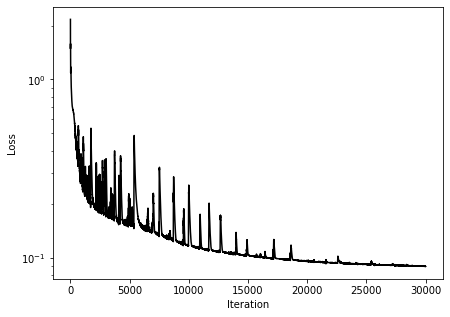

In [4]:
solver.plot_loss_history();

In [5]:
t0 = time()
try: 
  optim = tf.keras.optimizers.Adam(learning_rate=1e-5)
  solver.solve_with_TFoptimizer(optim, X_r, X_data, u_data, alpha = 0.2)
except:
  pass

print('\nTraining time: {} seconds'.format(time()-t0))
alert('2eme entrainement burgers2d')

Epoch 59_900: phi_r  4.2894e-06    phi_0  3.4145e-02    phi_b  5.1524e-02    total_loss  8.5673e-02
Training time: 3503.8622920513153 seconds


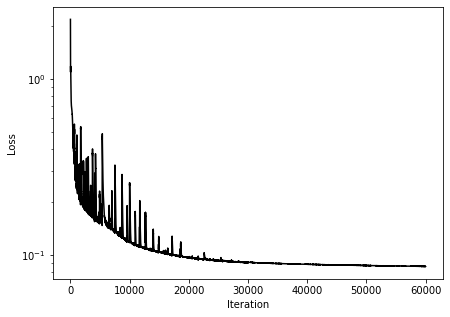

In [6]:
solver.plot_loss_history();

# vérification que ca fonctionne 

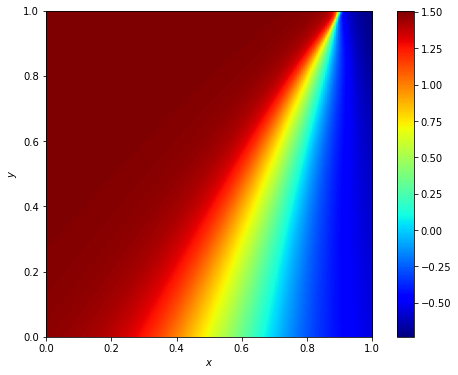

In [7]:
#model.load_weights('saved_models/best_weight-hubert.h5')

N = 150

# compute solution using PINN
xspace = np.linspace(0,1,N)
yspace = np.linspace(0,1,N)
tfinal =  1.5 * np.ones(N*N)

X, Y = np.meshgrid(xspace, yspace)
Xgrid = np.vstack([tfinal.flatten(), X.flatten(), Y.flatten()]).T
upred = model(tf.cast(Xgrid,DTYPE))

# reshape for plotting
U = upred.numpy().reshape(N,N)

# plot solution
fig = plt.figure(figsize=(9,6))
ax = fig.add_subplot(111)
ax.set_xlabel('$x$')
ax.set_ylabel('$y$')  
img = ax.imshow(U, cmap='jet', origin='lower', extent=[0.,1.,0.,1.]);
fig.colorbar(img);